# LD decay — new panel vs the old GrENE-Net 231 SNP catalog

**Question**: does the new panel have the same LD structure as the GrENE-Net phase-1 panel,
and if not, is the difference about *which sites* each panel contains or about *how genotypes are called*?

**Tracks** (same 231 founders, same filters):
Track names in the CSVs: `arch3_*` = the new panel, `grenenet_*` = the old GrENE-Net panel.
- `arch3_q`, `grenenet_q` — each panel's SNPs passing the quality filters.
- `arch3_maf10`, `grenenet_maf10` — MAF >= 0.1, call rate >= 0.9. Kim et al. 2007 used 'non-singleton' SNPs in 19 accessions, which is MAF >= 2/19 ~ 10%; with 231 founders the equivalent is a MAF floor, not a count of 2.
- `arch3_ns`, `grenenet_ns` (in the CSVs, not plotted) — non-singleton SNPs (minor-allele count >= 2, no MAF floor, call rate >= 0.9), the filter of Kim et al. 2007.
- `arch3_shared`, `grenenet_shared` — exact (pos, ref, alt) sites passing the filters in **both** panels,
  each evaluated with its **own** genotypes. `q` vs `q` mixes ascertainment and calling;
  `shared` vs `shared` isolates calling.

**Design**
- Identical MAF >= 0.05 and call rate >= 0.9 in both panels (r² is bounded by the MAF difference of two
  sites, so unequal floors would make the curves incomparable). new-panel missingness is structured by
  founder (153/231 founders are PanGenie-genotyped from short reads).
- No positional thinning (it would destroy the <10 kb resolution). 5,000 random focal SNPs per chromosome,
  1 kb distance bins to 25 kb; every quality partner within 100 kb kept.
- Founders are inbred: haploid 0/1 genotypes, pairwise-complete r² (pairs need >= 100 jointly called founders).
  Distance-0 pairs (multi-allelic decomposed records) excluded. Raw r², no small-sample correction
  (random baseline ~ 1/231).

SNPs only (ref and alt length 1); SVs/indels are excluded because their genotype calls are less reliable.

**Code**: `qc/_compute_ld_decay_panels.py`.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'font.size':9,'axes.linewidth':0.6})
G = "/global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection"
PLOTS = f"{G}/notebooks/plots"; os.makedirs(PLOTS, exist_ok=True)
df = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{G}/qc/results/ld_decay_panels_chr*.csv"))],
               ignore_index=True)
df['mid'] = (df.bin_lo + df.bin_hi) / 2          # bp, bin centre
df.loc[df.bin_lo == 1, 'mid'] = 250                    # first bin spans 1-500 bp
print(sorted(df.chrom.unique()))
# genome-wide: pair-weighted mean across chromosomes
df['sum_r2'] = df.mean_r2.fillna(0) * df.n_pairs
gw = df.groupby(['track','bin_lo','bin_hi','mid'], as_index=False)[['sum_r2','n_pairs']].sum()
gw['mean_r2'] = gw.sum_r2 / gw.n_pairs
gw.pivot(index='bin_lo', columns='track', values='mean_r2').round(3).loc[lambda x: x.index <= 25000]


['Chr1', 'Chr2', 'Chr3', 'Chr4', 'Chr5']


track,arch3_maf10,arch3_ns,arch3_q,arch3_shared,grenenet_maf10,grenenet_ns,grenenet_q,grenenet_shared
bin_lo,,,,,,,,
1,0.635,0.194,0.493,0.478,0.549,0.127,0.392,0.470
500,0.515,0.150,0.390,0.367,0.422,0.093,0.295,0.361
1000,0.422,0.118,0.310,0.294,0.342,0.075,0.236,0.292
2000,0.339,0.092,0.243,0.231,0.277,0.062,0.190,0.234
3000,0.277,0.076,0.198,0.189,0.226,0.053,0.158,0.190
4000,0.232,0.065,0.167,0.163,0.196,0.047,0.137,0.163
5000,0.198,0.058,0.144,0.142,0.171,0.043,0.120,0.142
6000,0.173,0.053,0.128,0.127,0.153,0.039,0.109,0.125
7000,0.152,0.048,0.113,0.114,0.137,0.037,0.099,0.112


## Genome-wide LD decay

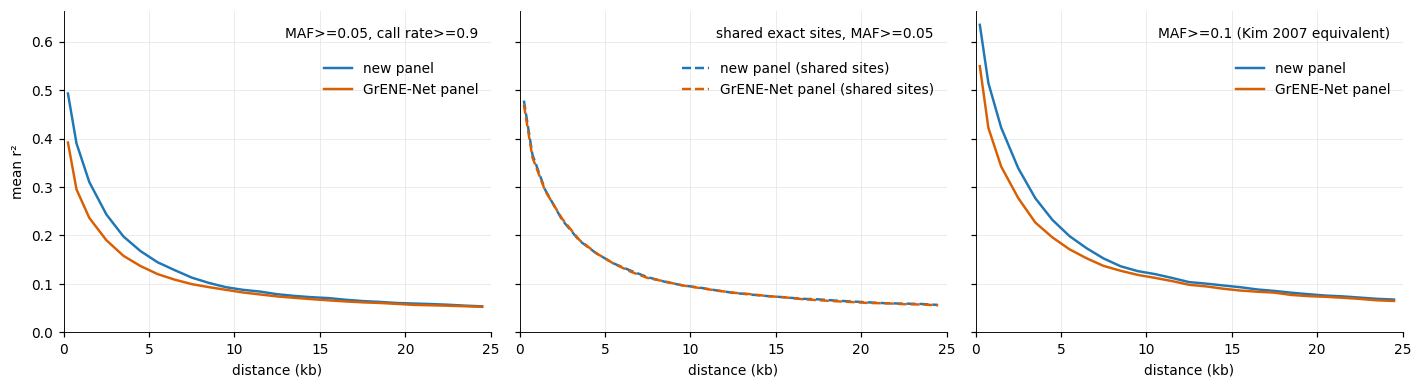

In [2]:

DISPLAY = {'arch3_q':'new panel', 'grenenet_q':'GrENE-Net panel', 'arch3_maf10':'new panel', 'grenenet_maf10':'GrENE-Net panel',
           'arch3_ns':'new panel', 'grenenet_ns':'GrENE-Net panel', 'arch3_shared':'new panel (shared sites)', 'grenenet_shared':'GrENE-Net panel (shared sites)'}
STYLE = {'arch3_q':('#1f77b4','-'), 'grenenet_q':('#d95f02','-'),
         'arch3_ns':('#1f77b4','-'), 'grenenet_ns':('#d95f02','-'),
         'arch3_maf10':('#1f77b4','-'), 'grenenet_maf10':('#d95f02','-'),
         'arch3_shared':('#1f77b4','--'), 'grenenet_shared':('#d95f02','--')}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, tracks, note in ((axes[0], ['arch3_q','grenenet_q'], 'MAF>=0.05, call rate>=0.9'),
                         (axes[2], ['arch3_maf10','grenenet_maf10'], 'MAF>=0.1 (Kim 2007 equivalent)'),
                         (axes[1], ['arch3_shared','grenenet_shared'], 'shared exact sites, MAF>=0.05')):
    for t in tracks:
        d = gw[gw.track == t]
        d = d[d.bin_hi <= 26000]; ax.plot(d.mid/1000, d.mean_r2, color=STYLE[t][0], ls=STYLE[t][1], lw=1.6, label=DISPLAY[t])
    ax.set_xlim(0, 25); ax.set_xlabel('distance (kb)')
    ax.annotate(note, (0.97, 0.95), xycoords='axes fraction', ha='right', va='top')
    ax.legend(frameon=False, loc='upper right', bbox_to_anchor=(1, 0.88)); ax.grid(color='#e6e6e6', lw=0.5)
    for s in ('top','right'): ax.spines[s].set_visible(False)
axes[0].set_ylabel('mean r²'); axes[0].set_ylim(0, None)
fig.tight_layout(); fig.savefig(f"{PLOTS}/ld_decay_panels_genomewide.png", dpi=200); plt.show()


## Per chromosome

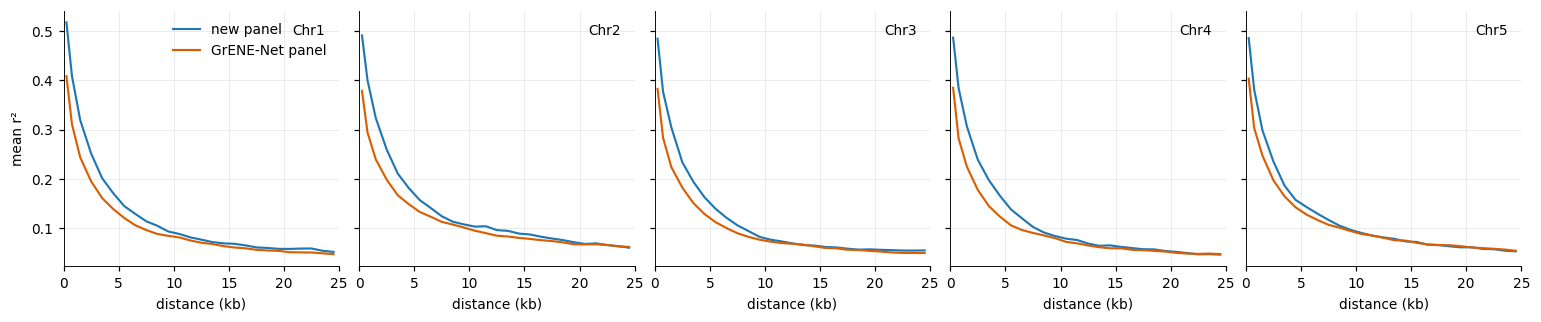

In [3]:

fig, axes = plt.subplots(1, 5, figsize=(14, 3), sharey=True)
for ax, (c, d) in zip(axes, df.groupby('chrom')):
    for t in ['arch3_q','grenenet_q']:
        e = d[(d.track == t) & (d.bin_hi <= 26000)]; ax.plot(e.mid/1000, e.mean_r2, color=STYLE[t][0], lw=1.4, label=DISPLAY[t])
    ax.set_xlim(0, 25); ax.annotate(c, (0.95, 0.95), xycoords='axes fraction', ha='right', va='top')
    ax.set_xlabel('distance (kb)'); ax.grid(color='#e6e6e6', lw=0.5)
    for s in ('top','right'): ax.spines[s].set_visible(False)
axes[0].set_ylabel('mean r²'); axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{PLOTS}/ld_decay_panels_by_chrom.png", dpi=200); plt.show()


## Half-decay distance

In [4]:

# distance at which mean r2 first falls to half of the shortest-bin value (log-linear interpolation)
def d_half(d):
    d = d.sort_values('mid'); target = d.mean_r2.iloc[0] / 2
    below = d[d.mean_r2 <= target]
    if below.empty: return np.nan
    j = d.index.get_loc(below.index[0])
    if j == 0: return d.mid.iloc[0]
    x0, x1 = np.log(d.mid.iloc[j-1]), np.log(d.mid.iloc[j]); y0, y1 = d.mean_r2.iloc[j-1], d.mean_r2.iloc[j]
    return float(np.exp(x0 + (target - y0) * (x1 - x0) / (y1 - y0)))
gw.groupby('track').apply(d_half).rename('distance_to_half_of_shortest_bin_r2_bp').round(0)


track
arch3_maf10        2805.0
arch3_ns           2269.0
arch3_q            2438.0
arch3_shared       2344.0
grenenet_maf10     2536.0
grenenet_ns        2360.0
grenenet_q         2342.0
grenenet_shared    2474.0
Name: distance_to_half_of_shortest_bin_r2_bp, dtype: float64